# 🧩 Sudoku Solver — Particle Swarm Optimization (PSO)

This notebook solves a 9×9 Sudoku puzzle using **PSO** — a population-based
metaheuristic inspired by the social behaviour of bird flocks.

After the solver finishes, an **animation** shows the grid being filled in
step by step.

---

### How it works

| Concept | Implementation |
|---|---|
| **Particle** | A 9×9 grid where every row is a permutation of 1–9 (clue cells fixed) |
| **Fitness** | Distinct values across all rows, columns, and 3×3 boxes — max = **243** |
| **Cognitive move** | Mutate toward the particle's personal best (swap two free cells in a random row) |
| **Social move** | Mutate toward the global best |
| **Stagnation restart** | Re-randomise the worst half of the swarm when stuck |


In [1]:
# Install dependencies (numpy and matplotlib are already in Colab,
# but this cell keeps the notebook self-contained)
!pip install numpy matplotlib -q

## 1 · Imports

In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

## 2 · Define the Puzzle

`0` marks an **empty cell**.  Replace this grid with any valid 9×9 puzzle.

In [3]:
# Classic "easy" puzzle — feel free to swap in a harder one.
# 0 = empty cell that PSO will fill.
PUZZLE = np.array([
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9],
])

print("Puzzle to solve:")
print(PUZZLE)

Puzzle to solve:
[[5 3 0 0 7 0 0 0 0]
 [6 0 0 1 9 5 0 0 0]
 [0 9 8 0 0 0 0 6 0]
 [8 0 0 0 6 0 0 0 3]
 [4 0 0 8 0 3 0 0 1]
 [7 0 0 0 2 0 0 0 6]
 [0 6 0 0 0 0 2 8 0]
 [0 0 0 4 1 9 0 0 5]
 [0 0 0 0 8 0 0 7 9]]


## 3 · Fitness Function

A perfect Sudoku has **9 distinct digits in every row, column, and 3×3 box**.

- 9 rows × 9 unique = 81
- 9 columns × 9 unique = 81
- 9 boxes × 9 unique = 81
- **Total perfect score = 243**

We *maximise* this count.

In [4]:
def fitness(grid):
    """
    Return the total number of distinct values across all rows,
    columns, and 3×3 boxes.  Perfect (solved) grid → 243.
    """
    score = 0
    for i in range(9):
        score += len(set(grid[i, :]))       # row i
        score += len(set(grid[:, i]))       # column i
    for br in range(3):
        for bc in range(3):
            box = grid[br*3:br*3+3, bc*3:bc*3+3]
            score += len(set(box.flatten()))  # 3×3 box
    return score

PERFECT_SCORE = 243  # target we are maximising toward

## 4 · Particle Class

Each **particle** is a candidate solution — one complete 9×9 grid.

**Key idea:** every row is initialised as a *random permutation of 1–9*
that keeps the clue cells in place.  This guarantees every row is always
valid; PSO only needs to fix the columns and boxes.

The **mutation** (our discrete "velocity") swaps two non-fixed cells within
a single row.

In [5]:
class Particle:
    def __init__(self, puzzle):
        self.puzzle   = puzzle
        self.fixed    = puzzle != 0          # Boolean mask — True where a clue exists
        self.position = self._random_grid()  # Initial random candidate solution
        self.best_pos = self.position.copy() # Personal best position
        self.best_fit = fitness(self.position)

    # ── Initialisation ─────────────────────────────────────────────────────
    def _random_grid(self):
        """
        Fill each row with a shuffled permutation of the digits that are
        still missing from that row (keeping all clue digits in place).
        """
        grid = self.puzzle.copy()
        for r in range(9):
            # digits not yet present in this row
            missing = [v for v in range(1, 10) if v not in grid[r]]
            random.shuffle(missing)
            mi = 0
            for c in range(9):
                if grid[r, c] == 0:          # empty cell → fill from missing
                    grid[r, c] = missing[mi]
                    mi += 1
        return grid

    # ── Mutation (discrete velocity) ───────────────────────────────────────
    def mutate(self, grid):
        """
        Randomly swap two non-fixed cells within a randomly chosen row.
        This is the PSO 'move' adapted for a discrete combinatorial space.
        """
        g   = grid.copy()
        row = random.randint(0, 8)
        free = [c for c in range(9) if not self.fixed[row, c]]
        if len(free) >= 2:
            c1, c2 = random.sample(free, 2)
            g[row, c1], g[row, c2] = g[row, c2], g[row, c1]  # swap
        return g

## 5 · PSO Solver

Each iteration every particle makes two moves:

1. **Cognitive** — mutate toward its own personal best
2. **Social** — mutate toward the global best

If neither improves the particle's personal best, the particle stays put.

When the swarm is **stagnant** (no global improvement for `stagnation_limit`
iterations) the worst half is re-randomised to escape local optima.

In [6]:
def pso_solve(puzzle,
              n_particles      = 200,   # swarm size — increase for harder puzzles
              max_iter         = 2000,  # maximum iterations before giving up
              stagnation_limit = 100):  # iterations without improvement → restart
    """
    Run the PSO loop.

    Returns
    -------
    best_grid : np.ndarray  — best solution found (may be perfect or near-perfect)
    history   : list of (iteration, grid) snapshots used for the animation
    """

    # ── Initialise swarm ───────────────────────────────────────────────────
    particles = [Particle(puzzle) for _ in range(n_particles)]

    # Seed the global best from the initial swarm
    best_fit  = max(p.best_fit for p in particles)
    best_grid = next(p.position for p in particles
                     if p.best_fit == best_fit).copy()

    history    = [(0, best_grid.copy())]   # snapshots for animation
    stagnation = 0
    prev_best  = best_fit

    # ── Main loop ──────────────────────────────────────────────────────────
    for it in range(1, max_iter + 1):

        for p in particles:

            # 1. Cognitive move — pull toward personal best
            cand = p.mutate(p.best_pos)
            f    = fitness(cand)
            if f >= p.best_fit:            # accept if at least as good
                p.best_pos = cand
                p.best_fit = f

            # 2. Social move — pull toward global best
            cand2 = p.mutate(best_grid)
            f2    = fitness(cand2)
            if f2 >= p.best_fit:
                p.best_pos = cand2
                p.best_fit = f2

            # 3. Update current position to personal best
            p.position = p.best_pos.copy()

        # Update global best
        for p in particles:
            if p.best_fit > best_fit:
                best_fit  = p.best_fit
                best_grid = p.best_pos.copy()

        # Save a snapshot every 50 iterations or whenever score improves
        if best_fit > prev_best or it % 50 == 0:
            history.append((it, best_grid.copy()))

        # ── Termination: perfect solution ─────────────────────────────────
        if best_fit == PERFECT_SCORE:
            history.append((it, best_grid.copy()))
            print(f"✅  Solved at iteration {it}  (score = {best_fit}/{PERFECT_SCORE})")
            break

        # ── Stagnation check ──────────────────────────────────────────────
        if best_fit == prev_best:
            stagnation += 1
        else:
            stagnation = 0
            prev_best  = best_fit

        if stagnation >= stagnation_limit:
            # Re-randomise the worst half of the swarm
            particles.sort(key=lambda p: p.best_fit)
            for p in particles[:n_particles // 2]:
                p.position = p._random_grid()
                p.best_pos = p.position.copy()
                p.best_fit = fitness(p.position)
            stagnation = 0

    if best_fit < PERFECT_SCORE:
        print(f"⚠️  Best score reached: {best_fit}/{PERFECT_SCORE} "
              f"— try increasing n_particles or max_iter")

    return best_grid, history

## 6 · Drawing & Animation Helpers

`draw_grid` renders a single frame:
- **Dark navy** digits = original clues
- **Red** digits = cells filled by PSO

`animate` wraps the snapshot list into a `FuncAnimation`.

In [7]:
def draw_grid(ax, grid, puzzle, frame_label=""):
    """Draw one Sudoku grid frame on the given Axes."""
    ax.clear()
    ax.set_xlim(0, 9)
    ax.set_ylim(0, 9)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(frame_label, fontsize=13, pad=8)

    # Light-grey background
    ax.add_patch(patches.Rectangle((0, 0), 9, 9,
                                   facecolor='#f0f0f0',
                                   edgecolor='black', lw=2))

    # Cell grid lines (thicker every 3rd line for box borders)
    for i in range(1, 9):
        lw = 2.5 if i % 3 == 0 else 0.5
        ax.axhline(i, color='black', lw=lw)
        ax.axvline(i, color='black', lw=lw)

    # Place digit text in each cell
    for r in range(9):
        for c in range(9):
            val    = grid[r, c]
            x, y   = c + 0.5, 8.5 - r   # row 0 → top of canvas
            is_clue = puzzle[r, c] != 0
            ax.text(x, y, str(val),
                    ha='center', va='center', fontsize=14,
                    color='#1a1a2e' if is_clue else '#e94560',
                    fontweight='bold' if is_clue else 'normal')


def animate(puzzle, history):
    """Build and return a FuncAnimation from the PSO snapshot history."""
    fig, ax = plt.subplots(figsize=(5, 5))
    fig.patch.set_facecolor('#ffffff')

    def update(frame_idx):
        it, grid = history[frame_idx]
        label = (f"Iteration {it}  |  "
                 f"Score {fitness(grid)}/{PERFECT_SCORE}")
        draw_grid(ax, grid, puzzle, label)

    ani = FuncAnimation(fig, update,
                        frames=len(history),
                        interval=400,     # ms between frames
                        repeat=False)
    plt.tight_layout()
    return ani

## 7 · Solve & Display

In [8]:
# ── Run the solver ────────────────────────────────────────────────────────
print("Starting PSO …\n")
solution, history = pso_solve(PUZZLE)

print(f"\nFinal grid (score {fitness(solution)}/{PERFECT_SCORE}):\n")
print(solution)

Starting PSO …

⚠️  Best score reached: 239/243 — try increasing n_particles or max_iter

Final grid (score 239/243):

[[5 3 2 6 7 8 4 1 9]
 [6 7 4 1 9 5 3 2 8]
 [1 9 8 4 3 2 5 6 7]
 [8 5 9 7 6 1 2 4 3]
 [4 2 6 8 9 3 7 5 1]
 [7 1 3 5 2 4 8 9 6]
 [9 6 1 3 5 7 2 8 4]
 [2 8 7 4 1 9 6 3 5]
 [3 4 5 2 8 6 1 7 9]]


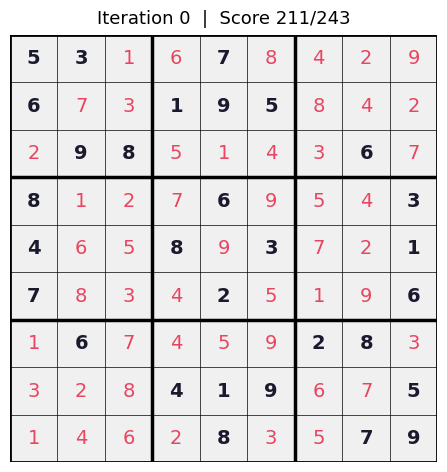

In [9]:
# ── Show animation ────────────────────────────────────────────────────────
# In Colab this renders as an interactive JavaScript widget.
ani = animate(PUZZLE, history)
HTML(ani.to_jshtml())

---
## Tips

| Goal | Change |
|---|---|
| Solve harder puzzles | Increase `n_particles` (300–500) and/or `max_iter` (3000–5000) |
| Speed up | Decrease `n_particles` or `stagnation_limit` |
| Use your own puzzle | Edit the `PUZZLE` array in **cell 2** |

> **Why PSO for Sudoku?**
> PSO is a population-based search method — it maintains many candidate solutions
> in parallel and uses both individual memory (personal best) and collective
> knowledge (global best) to guide the search.  For Sudoku the standard
> continuous velocity is replaced with a *row-swap mutation*, turning PSO into
> a discrete combinatorial optimiser.
